In [1]:
# Import necessary libraries

# Your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split

In [2]:
# Read the datafile "covid.csv"
df = pd.read_csv("covid.csv")

# Take a quick look at the dataframe
df.head()

,age,sex,cough,fever,chills,sore_throat,headache,fatigue,Urgency
0,30.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,47.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,49.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,59.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0


In [3]:
# Check if there are any missing or Null values
df.isna().sum()


age             6
sex             8
cough          11
fever          15
chills          4
sore_throat     6
headache        2
fatigue         4
Urgency         0
dtype: int64

In [4]:
### edTest(test_na) ###

# Find the number of rows with missing values
num_null = df.isna().any(axis=1).sum()
print("Number of rows with null values:", num_null)


Number of rows with null values: 37


In [5]:
# kNN impute the missing data
# Use a k value of 5

# Your code here
predictor_cols = df.columns.drop("Urgency")

imputer = KNNImputer(n_neighbors=5)
df[predictor_cols] = imputer.fit_transform(df[predictor_cols])

In [6]:
### edTest(test_impute) ###
# Replace the original dataframe with the imputed data, continue to use df for the dataframe

# Your code here
df.isna().sum()
    

age            0
sex            0
cough          0
fever          0
chills         0
sore_throat    0
headache       0
fatigue        0
Urgency        0
dtype: int64

## EDA

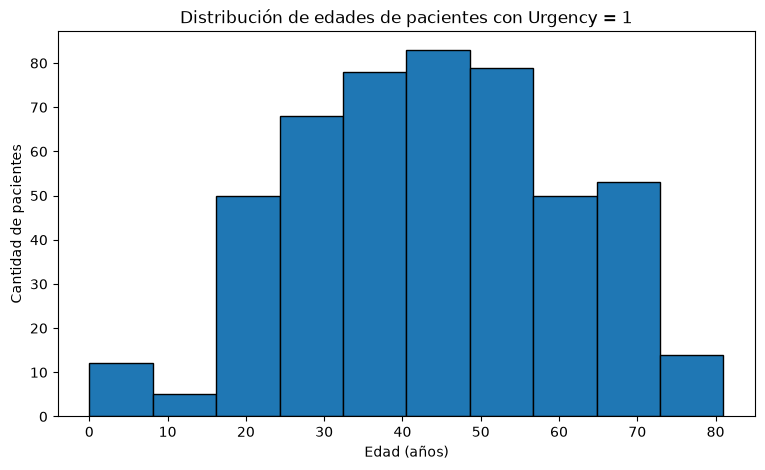

In [7]:
# Plot an appropriate graph to answer the following question
# Your code here
plt.figure(figsize=(9, 5))

plt.hist(
    df.loc[df["Urgency"] == 1, "age"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de pacientes")
plt.title("Distribución de edades de pacientes con Urgency = 1")
plt.show()

### ⏸ Which age group has the most urgent need for a hospital bed?

#### A. 60 - 70 

#### B. 50 - 60 

#### C. 20 - 30

#### D. 40 - 50

In [8]:
### edTest(test_chow1) ###
# Submit an answer choice as a string below (eg. if you choose option A, put 'A')
answer1 = 'D'


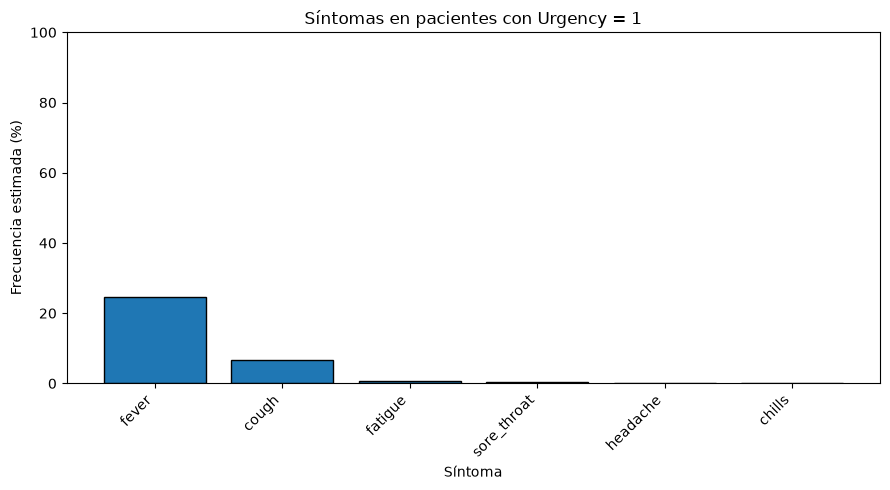

In [9]:
# Plot an appropriate graph to answer the following question    
# Your code here
symptoms = ["cough", "fever", "chills", "sore_throat", "headache", "fatigue"]

frequency = df.loc[df["Urgency"] == 1, symptoms].mean() * 100
frequency = frequency.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(frequency.index, frequency.values, edgecolor="black")
plt.xlabel("Síntoma")
plt.ylabel("Frecuencia estimada (%)")
plt.title("Síntomas en pacientes con Urgency = 1")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### ⏸ Among the following symptoms, which is the most common one for patients with urgent need of hospitalization?

#### A. Cough

#### B. Fever

#### C. Sore Throat

#### D. Fatigue

In [10]:
### edTest(test_chow2) ###
# Submit an answer choice as a string below (eg. if you choose option A, put 'A')
answer2 = 'B'


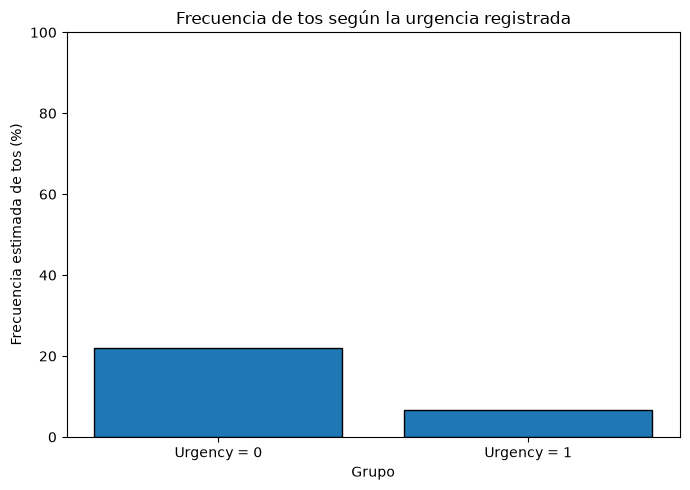

Urgency
0    21.89
1     6.63
Name: cough, dtype: float64


In [11]:
# Plot an appropriate graph to answer the following question    
# Your code here
# Plot an appropriate graph to answer the following question

cough_frequency = (
    df.groupby("Urgency")["cough"].mean().reindex([0, 1]) * 100
)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Urgency = 0", "Urgency = 1"],
    cough_frequency.values,
    edgecolor="black"
)

plt.xlabel("Grupo")
plt.ylabel("Frecuencia estimada de tos (%)")
plt.title("Frecuencia de tos según la urgencia registrada")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(cough_frequency.round(2))

### ⏸ As compared to patients with urgent need of hospitalization, patients with no urgency have cough as a more common symptom?

#### A. True

#### B. False

#### C. It is the same

#### D. Cannot say

In [12]:
### edTest(test_chow3) ###
# Submit an answer choice as a string below (eg. if you choose option A, put 'A')
answer3 = 'A'


### Train Test Split

In [13]:
### edTest(test_split) ###
# Split the data into train and test sets with 70% for training
# Use random state of 60 and set of data as the train split

# Your code here
df_train, df_test = train_test_split(
    df, test_size=0.3, random_state=60
)

In [14]:
# Save the train data into a csv called "covid_train.csv"
# Remember to not include the default indices
df_train.to_csv("covid_train.csv", index=False)
# Save the test data into a csv called "covid_test.csv"
# Remember to not include the default indices
df_test.to_csv("covid_test.csv", index=False)
